# LinkShield AI — Notebook 01: Data Audit & EDA

**Phase 1, Step 1 (Person 1 deliverable).** Downloads the official UCI PhiUSIIL dataset (ID 967), keeps only the URL and label columns, verifies the label mapping, audits data quality and produces the EDA charts and summary.

URLs are treated as inert text. Nothing in this notebook opens, resolves or requests any URL from the dataset. No model is trained here.

Runs from the project root, from `notebooks/`, or in Google Colab.

In [1]:
!pip -q install ucimlrepo --disable-pip-version-check

In [2]:
# Work from the project root so outputs land in reports/ and data/
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("Working directory:", Path.cwd())

Working directory: C:\Users\Seif Badreldin\Downloads\LinkShield_AI


In [3]:

from ucimlrepo import fetch_ucirepo

# Download official dataset
dataset = fetch_ucirepo(id=967)

# Load features and target
X = dataset.data.features
y = dataset.data.targets

# Inspect dataset
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget columns:")
print(y.columns.tolist())


Features shape: (235795, 54)
Target shape: (235795, 1)

Feature columns:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Target columns:
['label']


In [4]:

import pandas as pd

# Select only URL and label columns
df = pd.DataFrame({
    "url": X["URL"],
    "original_label": y["label"]
})

# Dataset information
print("Total records:", len(df))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check label distribution
print("\nOriginal label distribution:")
print(df["original_label"].value_counts(dropna=False))

# Check unique labels
print("\nUnique labels:")
print(df["original_label"].unique())

# Preview first 5 records without displaying URLs
print("\nFirst 5 labels:")
print(df[["original_label"]].head())


Total records: 235795

Missing values:
url               0
original_label    0
dtype: int64

Original label distribution:
original_label
1    134850
0    100945
Name: count, dtype: int64

Unique labels:
[1 0]

First 5 labels:
   original_label
0               1
1               1
2               1
3               1
4               1


In [5]:

# Verify original labels
assert set(df["original_label"].unique()) == {0, 1}

# Convert to project label convention
df["is_phishing"] = 1 - df["original_label"]

# Verify conversion
assert (df.loc[df["original_label"] == 0, "is_phishing"] == 1).all()
assert (df.loc[df["original_label"] == 1, "is_phishing"] == 0).all()

print("Project label distribution:")
print(df["is_phishing"].value_counts())

print("\nLabel mapping verification: PASSED")


Project label distribution:
is_phishing
0    134850
1    100945
Name: count, dtype: int64

Label mapping verification: PASSED


In [6]:

# Check empty and whitespace-only URLs
empty_urls = df["url"].astype(str).str.strip().eq("").sum()

# Check exact duplicate URL strings
duplicate_urls = df["url"].duplicated().sum()

# Check conflicting labels for identical URLs
conflicting_urls = (
    df.groupby("url")["original_label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Empty URLs:", empty_urls)
print("Exact duplicate URLs:", duplicate_urls)
print("URLs with conflicting labels:", conflicting_urls)


Empty URLs: 0
Exact duplicate URLs: 425
URLs with conflicting labels: 0


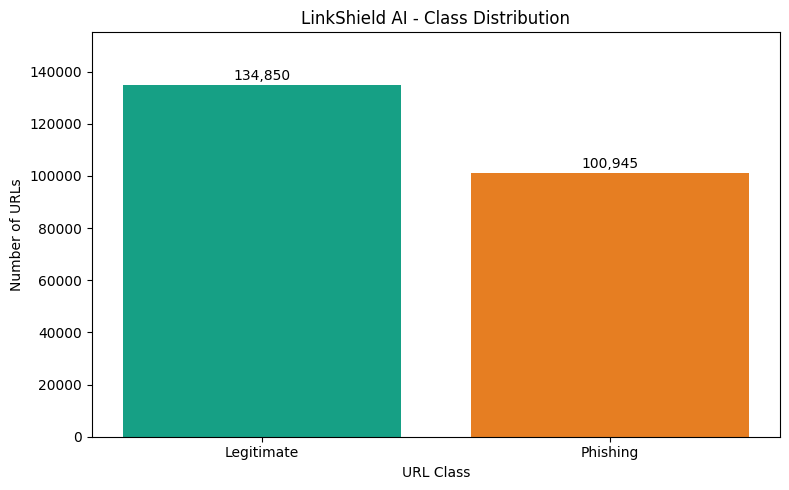

In [7]:

import matplotlib.pyplot as plt

# Count classes
class_counts = df["is_phishing"].value_counts().sort_index()

# Create chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Legitimate", "Phishing"],
    [class_counts[0], class_counts[1]],
    color=["#16A085", "#E67E22"]
)

plt.title("LinkShield AI - Class Distribution")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2000,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.ylim(0, max(class_counts) * 1.15)
plt.tight_layout()

# Save chart
plt.savefig(
    "eda_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


URL Length Statistics:
                count       mean        std   min   25%   50%   75%     max
is_phishing                                                                
0            134850.0  27.228610   4.815612  16.0  24.0  27.0  30.0    58.0
1            100945.0  46.238774  61.074850  14.0  26.0  34.0  48.0  6097.0


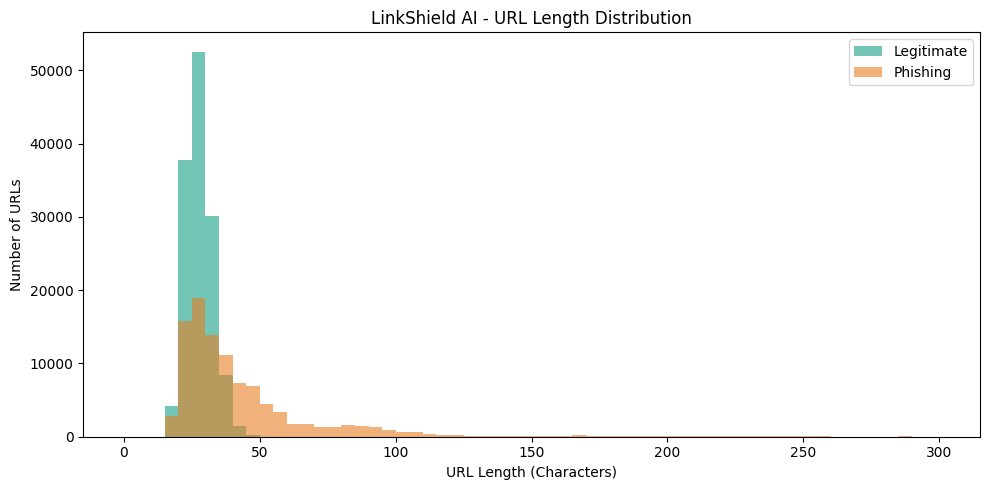

In [8]:

import matplotlib.pyplot as plt

# Calculate URL length
df["url_length"] = df["url"].str.len()

# Show statistics
print("URL Length Statistics:")
print(df.groupby("is_phishing")["url_length"].describe())

# Plot URL length distribution
plt.figure(figsize=(10, 5))

plt.hist(
    df[df["is_phishing"] == 0]["url_length"],
    bins=60,
    alpha=0.6,
    label="Legitimate",
    color="#16A085",
    range=(0, 300)
)

plt.hist(
    df[df["is_phishing"] == 1]["url_length"],
    bins=60,
    alpha=0.6,
    label="Phishing",
    color="#E67E22",
    range=(0, 300)
)

plt.title("LinkShield AI - URL Length Distribution")
plt.xlabel("URL Length (Characters)")
plt.ylabel("Number of URLs")
plt.legend()
plt.tight_layout()

plt.savefig(
    "eda_url_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [9]:

import json
import os

# Create reports folder
os.makedirs("reports", exist_ok=True)

# Build EDA summary from actual results
eda_summary = {
    "total_records": int(len(df)),
    "legitimate_count": int((df["is_phishing"] == 0).sum()),
    "phishing_count": int((df["is_phishing"] == 1).sum()),
    "missing_urls": int(df["url"].isna().sum()),
    "empty_urls": int(
        df["url"].fillna("").str.strip().eq("").sum()
    ),
    "exact_duplicate_urls": int(df["url"].duplicated().sum()),
    "conflicting_label_urls": int(conflicting_urls),
    "url_length_statistics": {
        "legitimate": {
            "mean": float(
                df.loc[df["is_phishing"] == 0, "url_length"].mean()
            ),
            "median": float(
                df.loc[df["is_phishing"] == 0, "url_length"].median()
            ),
            "max": int(
                df.loc[df["is_phishing"] == 0, "url_length"].max()
            )
        },
        "phishing": {
            "mean": float(
                df.loc[df["is_phishing"] == 1, "url_length"].mean()
            ),
            "median": float(
                df.loc[df["is_phishing"] == 1, "url_length"].median()
            ),
            "max": int(
                df.loc[df["is_phishing"] == 1, "url_length"].max()
            )
        }
    }
}

# Save JSON file
with open("reports/eda_summary.json", "w") as f:
    json.dump(eda_summary, f, indent=4)

# Move previously generated charts
import shutil

for filename in [
    "eda_class_distribution.png",
    "eda_url_length_distribution.png"
]:
    if os.path.exists(filename):
        shutil.copy2(filename, f"reports/{filename}")
    else:
        print("Missing chart:", filename)

print("EDA summary saved successfully!")
print("Files in reports folder:")
print(os.listdir("reports"))


EDA summary saved successfully!
Files in reports folder:
['data_quality_summary.json', 'eda_class_distribution.png', 'eda_observations.md', 'eda_summary.json', 'eda_url_length_distribution.png', 'leakage_check.md', 'phase1_baseline_metrics.json', 'phase1_baseline_notes.md', 'phase1_confusion_matrix.png']


## Raw two-column export

Exports only `url` and `is_phishing` for Person 2 and checks the SHA-256 against `data/manifest.json`. An existing export is never overwritten; it is only compared. The raw CSV is excluded from Git by `.gitignore`.

In [10]:
import hashlib

raw_path = Path("data/raw/person1_raw_labeled_urls.csv")
fresh_bytes = df[["url", "is_phishing"]].to_csv(index=False, lineterminator="\n").encode("utf-8")
fresh_sha = hashlib.sha256(fresh_bytes).hexdigest()

if raw_path.exists():
    existing_sha = hashlib.sha256(raw_path.read_bytes()).hexdigest()
    print("Existing export kept:", raw_path)
    print("Fresh download matches existing export:", fresh_sha == existing_sha)
else:
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    raw_path.write_bytes(fresh_bytes)
    print("Export written:", raw_path)

print("SHA-256 of fresh export:", fresh_sha)
manifest_path = Path("data/manifest.json")
if manifest_path.exists():
    expected = json.loads(manifest_path.read_text(encoding="utf-8"))["exported_csv_sha256"]
    print("Matches data/manifest.json:", fresh_sha == expected)

Existing export kept: data\raw\person1_raw_labeled_urls.csv
Fresh download matches existing export: True
SHA-256 of fresh export: fe2271b5e5f09dc9f013f669b76fbb483b1f5806b149ae409c4b09ea04b14190
Matches data/manifest.json: True


## A few URL strings, shown as inert text

Dots are replaced with `[.]` and the scheme is broken so that nothing below can be rendered as a clickable link. These are examples only, not evidence of anything.

In [11]:
def defang(u):
    return u.replace("http", "hxxp", 1).replace(".", "[.]")

for label, name in [(0, "Legitimate"), (1, "Phishing")]:
    print(name)
    sample = df.loc[(df["is_phishing"] == label) & (df["url_length"] <= 70), "url"].sample(3, random_state=42)
    for u in sample:
        print("   ", defang(u))

Legitimate
    hxxps://www[.]atelierozmoz[.]be
    hxxps://www[.]diemon[.]com
    hxxps://www[.]wausauschools[.]org
Phishing
    hxxp://www[.]do6fli[.]a1free9bird[.]com
    hxxps://maildinshaakckjnw567[.]firebaseapp[.]com/
    hxxps://23247-5519[.]s3[.]webspace[.]re/s/area_cliente/informacion[.]html


## Observations (written from the values computed above)

In [12]:
s = eda_summary
L, P = s["url_length_statistics"]["legitimate"], s["url_length_statistics"]["phishing"]
observations = f"""# EDA observations

- Total records: {s['total_records']:,}; legitimate {s['legitimate_count']:,}; phishing {s['phishing_count']:,}.
- Original labels were verified and converted to project labels.
- No null/empty URL values were observed.
- There are {s['exact_duplicate_urls']} exact-string duplicate rows and {s['conflicting_label_urls']} conflicting-label URL groups. Do not confuse exact-string duplicates with normalized duplicates.
- Mean URL length: legitimate {L['mean']:.2f}, phishing {P['mean']:.2f} characters.
- Median URL length: legitimate {L['median']:.0f}, phishing {P['median']:.0f} characters.
- Maximum URL length: legitimate {L['max']}, phishing {P['max']} characters.
- The histogram shows 0–300 characters for readability, while summary statistics include all URLs.
- These are descriptive findings only; do not claim predictive performance.
"""
assert s["missing_urls"] == 0 and s["empty_urls"] == 0
Path("reports/eda_observations.md").write_bytes(observations.encode("utf-8"))
print(observations)

# Remove the working copies of the charts; the kept copies are in reports/
for filename in ["eda_class_distribution.png", "eda_url_length_distribution.png"]:
    if os.path.exists(filename) and os.path.exists(os.path.join("reports", filename)):
        os.remove(filename)
print("Outputs:", sorted(f for f in os.listdir("reports") if f.startswith("eda_")))

# EDA observations

- Total records: 235,795; legitimate 134,850; phishing 100,945.
- Original labels were verified and converted to project labels.
- No null/empty URL values were observed.
- There are 425 exact-string duplicate rows and 0 conflicting-label URL groups. Do not confuse exact-string duplicates with normalized duplicates.
- Mean URL length: legitimate 27.23, phishing 46.24 characters.
- Median URL length: legitimate 27, phishing 34 characters.
- Maximum URL length: legitimate 58, phishing 6097 characters.
- The histogram shows 0–300 characters for readability, while summary statistics include all URLs.
- These are descriptive findings only; do not claim predictive performance.

Outputs: ['eda_class_distribution.png', 'eda_observations.md', 'eda_summary.json', 'eda_url_length_distribution.png']
